In [ ]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))
import operator
from typing import Annotated, TypedDict

from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel

from utils.models import ModelName, Models


In [ ]:
models = Models()
model_name = ModelName.POOLSIDE_LAGUNA.value
llm = models.create_nvidia_model(model_name)


In [ ]:
class OverallState(TypedDict):
    topic: str
    subjects: list
    jokes: Annotated[list, operator.add]
    best_selected_joke: str


class BestJoke(BaseModel):
    id: int


class JokeState(BaseModel):
    subject: str


class Joke(BaseModel):
    joke: str


class Subjects(BaseModel):
    subjects: list[str]


In [30]:
GENERATE_SUBJECTS_PROMPT = (
    """Generate 3 different subjects based on the topic:{topic}"""
)
GENERATE_JOKE_PROMPT = """generate a funny and witty joke about the subject:{subject}"""
PICK_BEST_JOKE_PROMPT = """Pick the best joke on the topic {topic} from the list and return the ID, the  ID of the first joke should start from 0 for the  jokes in the list.Here is the list of jokes:\n\n{jokes}"""

In [ ]:
def generate_subjects(state: OverallState):
    topic = state["topic"]
    prompt = GENERATE_SUBJECTS_PROMPT.format(topic=topic)

    response = llm.with_structured_output(Subjects).invoke(prompt)

    return {"subjects": response.subjects}


In [ ]:
def generate_joke(state: JokeState):
    subject = state["subject"]
    prompt = GENERATE_JOKE_PROMPT.format(subject=subject)
    response = llm.with_structured_output(Joke).invoke(prompt)
    return {"jokes": [response.joke]}

In [31]:
def best_joke(state: OverallState):
    topic = state["topic"]
    jokes = state["jokes"]

    prompt = PICK_BEST_JOKE_PROMPT.format(topic=topic, jokes=jokes)
    response = llm.with_structured_output(BestJoke).invoke(prompt)
    best_selected_joke = jokes[response.id]
    return {"best_selected_joke": best_selected_joke}

In [ ]:
def should_continue(state: OverallState):
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]

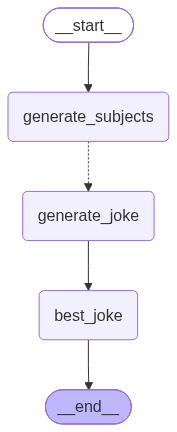

In [32]:
builder = StateGraph(OverallState)
builder.add_node("generate_subjects", generate_subjects)
builder.add_node("generate_joke", generate_joke)
builder.add_node("best_joke", best_joke)
builder.add_edge(START, "generate_subjects")
builder.add_conditional_edges("generate_subjects", should_continue, ["generate_joke"])
builder.add_edge("generate_joke", "best_joke")
builder.add_edge("best_joke", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [33]:
response = graph.invoke({"topic": "politics"})

d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'poolside/laguna-xs-2.1' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(
d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'poolside/laguna-xs-2.1' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(
d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'poolside/laguna-xs-2.1' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(
d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'poolside/laguna-xs-2.1' is not known to support structured output. Your output may fail 

In [40]:
response["best_selected_joke"]

"Why did the social media algorithm get kicked out of the political discussion group? Because it kept saying, 'You might also like to agree with yourself in multiple languages, but here's your cousin's conspiracy theory about pizza being a vegetable—again.'"